## Curso Integral de Econometría 
### Econometría de datos panel con Python
### Tema: Análisis y validación de supuestos iniciales
### Subtema: El ingreso y la convergencia económica en América Latina
### Sesión: 13
### Fecha: 20/11/2026
### Asesor: Alexis Adonai Morales Alberto

#### **Módulos y configuración**

In [2]:
# Módulos completos 

import json 
import warnings
import hashlib
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Submódulos y/o clases

from pathlib import Path
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.multitest import multipletests

In [3]:
# Configuración inicial

BASE = Path(
    "E:\Econometrics Data Lab\Curso integral de econometría\Datos de panel\PANEL_SEP26"
)

SALIDA = BASE / "Resultados" / "S13_Analisis_Previo"
SALIDA.mkdir(parents=True, exist_ok=True)
MOSTRAR_GRAFICOS = globals().get("MOSTRAR_GRAFICOS", True)
ALPHA = 0.05
variables = ["ln_pib_pc", "inversion_fbkf", "apertura_comercial", "inflacion"]
controles = variables[1:]
paises_S12 = ["BRA", "CHL", "COL", "CRI", "ECU", "MEX", "PER", "URY"]
Nombres = {"BRA": "Brasil", "CHL": "Chile", "COL": "Colombia", "CRI": "Costa Rica",
           "ECU": "Ecuador", "MEX": "México", "PER": "Perú", "URY": "Uruguay"}
EDL_NARANJA = "#F04A1D"
EDL_APOYO = "#D3D3D3"
EDL_GRIS = "#6C6259"
colores = ["#F04A1D", "#84517F", "#65773E", "#B5790C", "#A95D49", "#6C6259"]
plt.rcParams.update({"font.sans-serif": ["DejaVu Sans", "Arial"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#4D565E", "xtick.color": "#4D565E", "ytick.color": "#4D565E",
    "axes.titleweight": "bold", "svg.fonttype": "none", "font.size": 10})

#### **Lectura de datos**

In [4]:
candidatos = [BASE / "Datos/Datos_AL_Panel.csv", BASE / "Datos_AL_Panel.csv",
              BASE / "Resultados/S12_Datos_WB_Panel/Datos_AL_Panel.csv"]
if "df_dinamico" in globals():
    Original = df_dinamico.copy(deep=True)
    fuente = "Objeto df_dinamico del usuario; S13 no lo modifica"
else:
    ruta = next((p for p in candidatos if p.is_file()), None)
    if ruta is None:
        raise FileNotFoundError("Coloca Datos_AL_Panel.csv en Datos/ o junto al script.")
    Original = pd.read_csv(ruta)
    fuente = str(ruta)
print("\n1. Fuente:", fuente)
print(Original.head().to_string(index=False))


1. Fuente: E:\Econometrics Data Lab\Curso integral de econometría\Datos de panel\PANEL_SEP26\Datos\Datos_AL_Panel.csv
pais  anio  inflacion  inversion_fbkf  apertura_comercial      pib_pc  ln_pib_pc  ln_pib_pc_rezagado
 BRA  2011   6.636450       20.608964           23.934405 9067.993163   9.112506            9.081670
 BRA  2012   5.403499       20.716713           25.114274 9167.499239   9.123420            9.112506
 BRA  2013   6.204311       20.911922           25.785957 9366.739324   9.144920            9.123420
 BRA  2014   6.329040       19.873029           24.685406 9338.342783   9.141884            9.144920
 BRA  2015   9.029901       17.835807           26.953626 8936.196617   9.097865            9.141884


#### **Auditoria de datos: Integridad**

In [5]:
necesarias = ["pais", "anio", "pib_pc", "ln_pib_pc", "ln_pib_pc_rezagado"] + controles
if not set(necesarias).issubset(Original.columns):
    raise ValueError("Columnas faltantes: " + str(set(necesarias)-set(Original.columns)))
Panel = Original.copy(deep=True)
if Panel["pais"].isna().any():
    raise ValueError("Identificador de país vacío.")
Panel["pais"] = Panel.pais.astype(str).str.strip().str.upper()
for v in ["anio", "pib_pc", "ln_pib_pc", "ln_pib_pc_rezagado"] + controles:
    Panel[v] = pd.to_numeric(Panel[v], errors="raise")
if Panel[necesarias].isna().any().any():
    raise ValueError("La base de S12 tiene NA: revisar antes de definir una muestra común.")
if not np.isfinite(Panel[["anio", "pib_pc", "ln_pib_pc", "ln_pib_pc_rezagado"]+controles]).all().all():
    raise ValueError("Hay valores no finitos; revisar antes de continuar.")
if not np.allclose(Panel.anio, Panel.anio.round()):
    raise ValueError("Se esperan años enteros.")
Panel["anio"] = Panel.anio.astype(int)
if Panel.duplicated(["pais", "anio"]).any():
    raise ValueError("Clave país-año duplicada: no agregar ni borrar sin revisar.")
if Panel.pais.eq("").any() or Panel.pib_pc.le(0).any():
    raise ValueError("Identificador vacío o PIB no positivo; no puede aplicarse el logaritmo.")
Panel = Panel.sort_values(["pais", "anio"]).reset_index(drop=True)
error_log = float(np.max(np.abs(Panel.ln_pib_pc-np.log(Panel.pib_pc))))
if error_log > 1e-8:
    raise ValueError("ln_pib_pc no coincide con log(pib_pc).")
print(f"\n2. Claves únicas y valores finitos. Error máximo de logaritmo={error_log:.3g}.")
print("Las tasas/porcentajes se conservan en nivel; no tomar log(inflacion) si hay deflación.")



2. Claves únicas y valores finitos. Error máximo de logaritmo=1.78e-15.
Las tasas/porcentajes se conservan en nivel; no tomar log(inflacion) si hay deflación.


#### **Balanceo real, fechas compartidas y huecos**

In [11]:
paises = sorted(Panel.pais.unique())
anios = sorted(Panel.anio.unique())
N, T, NT = len(paises), len(anios), len(Panel)
Cobertura = Panel.groupby("pais").anio.agg(["min", "max", "count"])
Cobertura["Huecos_internos"] = Cobertura["max"]-Cobertura["min"]+1-Cobertura["count"]
Cobertura["Continuo"] = Cobertura.Huecos_internos.eq(0)
Malla = Panel.groupby(["pais", "anio"]).size().unstack(fill_value=0)
balanceado = bool(Malla.eq(1).all().all())
mensaje = f"Muestra recibida: {N} países, {T} años distintos, {NT} filas; balanceada={balanceado}."
print("\n3.", mensaje, "\n", Cobertura.to_string())
notas = []
notas.append(mensaje)
print("Balanceo exige las mismas fechas por país; no basta con igual número de filas.")
print("Países ausentes respecto a la muestra final de S12:", sorted(set(paises_S12)-set(paises)))
Cobertura.to_csv(SALIDA / "01_cobertura_panel.csv", encoding="utf-8-sig")
Malla.to_csv(SALIDA / "02_malla_pais_anio.csv", encoding="utf-8-sig")


3. Muestra recibida: 8 países, 12 años distintos, 96 filas; balanceada=True. 
        min   max  count  Huecos_internos  Continuo
pais                                              
BRA   2011  2022     12                0      True
CHL   2011  2022     12                0      True
COL   2011  2022     12                0      True
CRI   2011  2022     12                0      True
ECU   2011  2022     12                0      True
MEX   2011  2022     12                0      True
PER   2011  2022     12                0      True
URY   2011  2022     12                0      True
Balanceo exige las mismas fechas por país; no basta con igual número de filas.
Países ausentes respecto a la muestra final de S12: []


In [12]:
# Comprobar que cada celda representa ausencia (0) o disponibilidad (1)
if not Malla.isin([0, 1]).to_numpy().all():
    raise ValueError(
        "Malla contiene valores diferentes de 0 y 1 o valores faltantes. "
        "Revisa cómo se construyó la disponibilidad."
    )

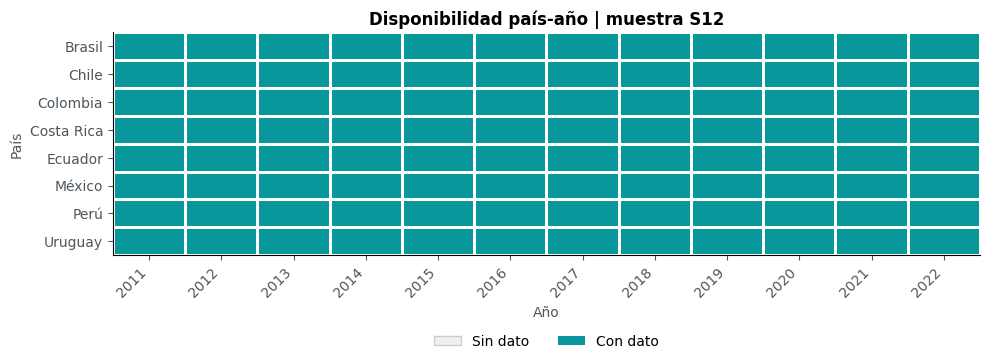

In [14]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
n_paises, n_anios = Malla.shape
colores = ["#EFEFEF", "#08989C"]
cmap = ListedColormap(colores)
norma = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)
fig, ax = plt.subplots(figsize=(10, 4))
ax.pcolormesh(
    np.arange(n_anios + 1),
    np.arange(n_paises + 1),
    Malla.to_numpy(dtype=float),
    cmap=cmap,
    norm=norma,
    edgecolors="white",
    linewidth=1
)
ax.set_xticks(
    np.arange(n_anios) + 0.5,
    labels=Malla.columns.astype(str),
    rotation=45,
    ha="right"
)
ax.set_yticks(
    np.arange(n_paises) + 0.5,
    labels=[Nombres.get(p, p) for p in Malla.index]
)
ax.invert_yaxis()
ax.set(
    title="Disponibilidad país-año | muestra S12",
    xlabel="Año",
    ylabel="País"
)
ax.legend(
    handles=[
        Patch(facecolor=colores[0], edgecolor="#CCCCCC", label="Sin dato"),
        Patch(facecolor=colores[1], label="Con dato")
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.30),
    ncol=2,
    frameon=False
)
fig.tight_layout()
SALIDA.mkdir(parents=True, exist_ok=True)
fig.savefig(SALIDA / "G01_cobertura.png", dpi=500, bbox_inches="tight")
fig.savefig(SALIDA / "G01_cobertura.svg", bbox_inches="tight")
if MOSTRAR_GRAFICOS:
    plt.show()

plt.close(fig)


#### **Construcción de rezagos por fecha**

In [15]:
hist_actual = Panel[["pais", "anio", "ln_pib_pc"]].copy()
hist_previa = Panel[["pais", "anio", "ln_pib_pc_rezagado"]].rename(
    columns={"ln_pib_pc_rezagado": "ln_pib_pc"})
hist_previa["anio"] = hist_previa.anio-1
historia_apilada = pd.concat([hist_actual, hist_previa], ignore_index=True)
rangos_historia = historia_apilada.groupby(["pais", "anio"]).ln_pib_pc.agg(["min", "max"])
if (rangos_historia["max"]-rangos_historia["min"]).gt(1e-8).any():
    raise ValueError("El rezago guardado no coincide con el nivel de la fecha anterior.")
Historia_y = historia_apilada.groupby(["pais", "anio"], as_index=False).ln_pib_pc.first()
for k in range(1, 5):
    aux = Historia_y.rename(columns={"ln_pib_pc": f"L{k}_ln_pib_pc"}).copy()
    aux["anio"] += k
    Panel = Panel.merge(aux, on=["pais", "anio"], how="left", validate="one_to_one")
assert np.allclose(Panel.L1_ln_pib_pc, Panel.ln_pib_pc_rezagado, atol=1e-8)
Panel["d_ln_pib_pc"] = Panel.ln_pib_pc-Panel.L1_ln_pib_pc
Panel["L1_d_ln_pib_pc"] = Panel.L1_ln_pib_pc-Panel.L2_ln_pib_pc
Panel["crecimiento_pct"] = 100*np.expm1(Panel.d_ln_pib_pc)
Panel.head()

,pais,anio,inflacion,inversion_fbkf,apertura_comercial,pib_pc,ln_pib_pc,ln_pib_pc_rezagado,L1_ln_pib_pc,L2_ln_pib_pc,L3_ln_pib_pc,L4_ln_pib_pc,d_ln_pib_pc,L1_d_ln_pib_pc,crecimiento_pct
0,BRA,2011,6.636450,20.608964,23.934405,9067.993163,9.112506,9.081670,9.081670,NaN,NaN,NaN,0.030837,NaN,3.131699
1,BRA,2012,5.403499,20.716713,25.114274,9167.499239,9.123420,9.112506,9.112506,9.081670,NaN,NaN,0.010914,0.030837,1.097333
2,BRA,2013,6.204311,20.911922,25.785957,9366.739324,9.144920,9.123420,9.123420,9.112506,9.081670,NaN,0.021501,0.010914,2.173331
3,BRA,2014,6.329040,19.873029,24.685406,9338.342783,9.141884,9.144920,9.144920,9.123420,9.112506,9.081670,-0.003036,0.021501,-0.303164
4,BRA,2015,9.029901,17.835807,26.953626,8936.196617,9.097865,9.141884,9.141884,9.144920,9.123420,9.112506,-0.044019,-0.003036,-4.306398


In [16]:
Historia_X = Panel[["pais", "anio"]+controles].copy()
ruta_historia = BASE / "Datos/Panel_WDI_2010_2022_completo.csv"
if ruta_historia.is_file():
    aux = pd.read_csv(ruta_historia)
    aux = aux.loc[aux.pais.isin(paises), ["pais", "anio"]+controles].copy()
    solape = Panel[["pais", "anio"]+controles].merge(aux, on=["pais", "anio"], suffixes=("", "_aux"))
    coherente = len(solape) == len(Panel) and all(np.allclose(solape[v], solape[v+"_aux"], equal_nan=True) for v in controles)
    if coherente:
        Historia_X = aux
    else:
        print("Descarga auxiliar no coincide con el CSV; no se mezclan versiones de X.")
for k in [1, 2, 3]:
    aux = Historia_X.copy()
    aux["anio"] += k
    aux = aux.rename(columns={v: f"L{k}_{v}" for v in controles})
    Panel = Panel.merge(aux, on=["pais", "anio"], how="left", validate="one_to_one")
for v in controles:
    Panel["d_"+v] = Panel[v]-Panel["L1_"+v]
print("\n4. Historial recuperado del logaritmo:\n", Historia_y.groupby("pais").anio.agg(["min", "max", "count"]))
print("Rezagos por llave (país, año-k). Un hueco nunca se interpreta como un año consecutivo.")
print("No se ha estimado un modelo dinámico; sólo se construyeron variables.")


4. Historial recuperado del logaritmo:
        min   max  count
pais                   
BRA   2010  2022     13
CHL   2010  2022     13
COL   2010  2022     13
CRI   2010  2022     13
ECU   2010  2022     13
MEX   2010  2022     13
PER   2010  2022     13
URY   2010  2022     13
Rezagos por llave (país, año-k). Un hueco nunca se interpreta como un año consecutivo.
No se ha estimado un modelo dinámico; sólo se construyeron variables.


#### **Mostrar cantidatos(as) de niveles y diferencias para el modelo de panel dinámico**

In [17]:
columnas_D = ["d_ln_pib_pc", "L1_d_ln_pib_pc", "L2_ln_pib_pc"]+["d_"+v for v in controles]
Muestra_niveles = Panel.dropna(subset=["ln_pib_pc", "L1_ln_pib_pc"]+controles).copy()
Muestra_D = Panel.dropna(subset=columnas_D).copy()
Conteo_muestras = pd.concat([
    Panel.groupby("pais").size().rename("CSV_S12"),
    Muestra_niveles.groupby("pais").size().rename("Candidata_niveles"),
    Muestra_D.groupby("pais").size().rename("Candidata_diferencias")], axis=1).fillna(0).astype(int)
print("\n5. Filas por muestra candidata:\n", Conteo_muestras.to_string())
print("Los primeros años que desaparecen de diferencias se deben al rezago y su instrumento.")
print("La muestra final depende también de los instrumentos de X que se decidan en S14.")
Conteo_muestras.to_csv(SALIDA / "03_muestras_candidatas.csv", encoding="utf-8-sig")



5. Filas por muestra candidata:
       CSV_S12  Candidata_niveles  Candidata_diferencias
pais                                                   
BRA        12                 12                     11
CHL        12                 12                     11
COL        12                 12                     11
CRI        12                 12                     11
ECU        12                 12                     11
MEX        12                 12                     11
PER        12                 12                     11
URY        12                 12                     11
Los primeros años que desaparecen de diferencias se deben al rezago y su instrumento.
La muestra final depende también de los instrumentos de X que se decidan en S14.


#### **Unidades y estadística descriptiva**

In [18]:
Diccionario = pd.DataFrame([
    ["pib_pc", "NY.GDP.PCAP.KD", "PIB real por habitante", "USD constantes de 2015; no PPP"],
    ["ln_pib_pc", "log(NY.GDP.PCAP.KD)", "Logaritmo natural del PIB real por habitante", "Cambio x100 aproxima %"],
    ["inversion_fbkf", "NE.GDI.FTOT.ZS", "Formación bruta de capital fijo", "% del PIB; no inversión por trabajador"],
    ["apertura_comercial", "NE.TRD.GNFS.ZS", "Exportaciones + importaciones", "% del PIB; puede superar 100"],
    ["inflacion", "FP.CPI.TOTL.ZG", "Inflación del IPC", "% anual; puede ser negativa"]],
    columns=["Variable", "Codigo", "Concepto", "Unidad"])
Descriptivos = Panel[["pib_pc"]+variables+["crecimiento_pct"]].describe(percentiles=[.25, .5, .75]).T
print("\n6. Diccionario:\n", Diccionario.to_string(index=False))
print("\nResumen:\n", Descriptivos.round(4).to_string())
print("Una apertura superior a 100 % no es automáticamente un error; no se aplica winsorización.")
Diccionario.to_csv(SALIDA / "04_diccionario.csv", index=False, encoding="utf-8-sig")
Descriptivos.to_csv(SALIDA / "05_descriptivos.csv", encoding="utf-8-sig")


6. Diccionario:
           Variable              Codigo                                     Concepto                                 Unidad
            pib_pc      NY.GDP.PCAP.KD                       PIB real por habitante         USD constantes de 2015; no PPP
         ln_pib_pc log(NY.GDP.PCAP.KD) Logaritmo natural del PIB real por habitante                 Cambio x100 aproxima %
    inversion_fbkf      NE.GDI.FTOT.ZS              Formación bruta de capital fijo % del PIB; no inversión por trabajador
apertura_comercial      NE.TRD.GNFS.ZS                Exportaciones + importaciones           % del PIB; puede superar 100
         inflacion      FP.CPI.TOTL.ZG                            Inflación del IPC            % anual; puede ser negativa

Resumen:
                     count       mean        std        min        25%        50%         75%         max
pib_pc               96.0  9950.3396  3818.3681  5355.6893  6294.3868  9352.5411  12898.1292  18249.2912
ln_pib_pc            96

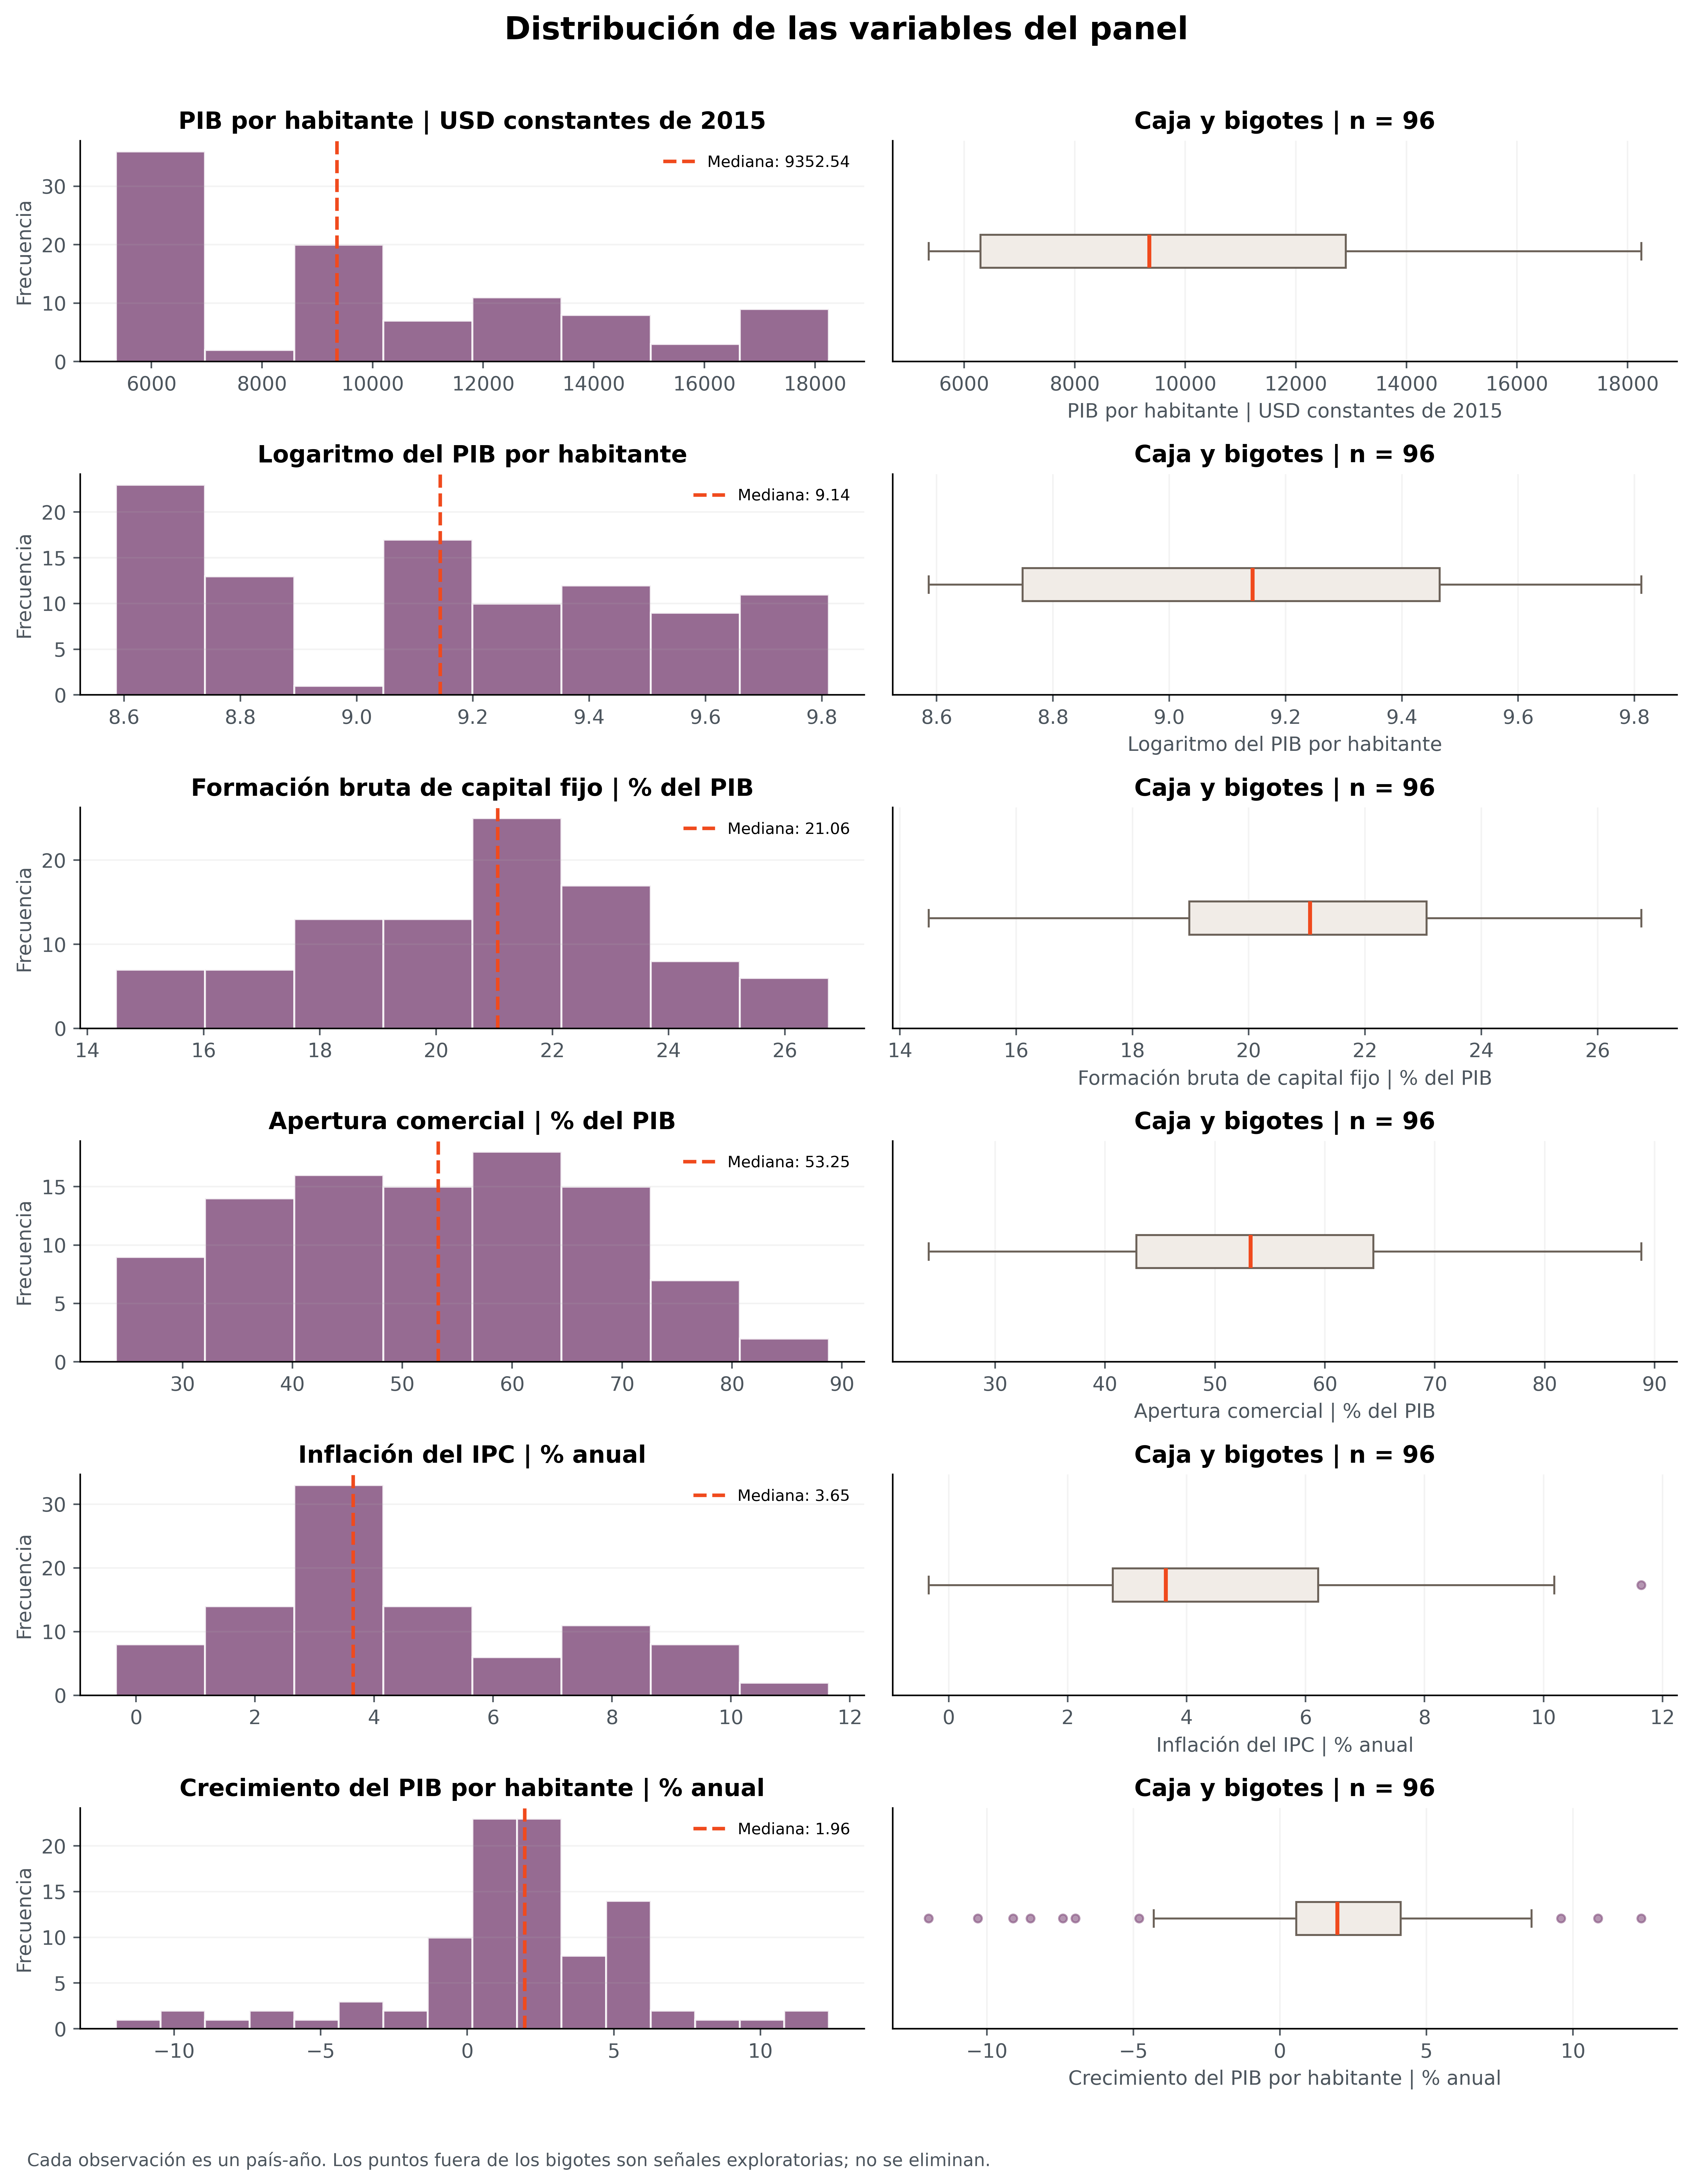

In [19]:
# Distribución de las variables: histograma y diagramas de caja

variables_grafico = list(
    dict.fromkeys(["pib_pc"] + variables + ["crecimiento_pct"])
)
etiquetas = {
    "pib_pc": "PIB por habitante | USD constantes de 2015",
    "ln_pib_pc": "Logaritmo del PIB por habitante",
    "inversion_fbkf": "Formación bruta de capital fijo | % del PIB",
    "apertura_comercial": "Apertura comercial | % del PIB",
    "inflacion": "Inflación del IPC | % anual",
    "crecimiento_pct": "Crecimiento del PIB por habitante | % anual"
}
fig, ejes = plt.subplots(
    len(variables_grafico), 2,
    figsize=(12, 2.6 * len(variables_grafico)),
    squeeze=False,
    dpi = 500
)
for fila, variable in enumerate(variables_grafico):
    datos = (
        pd.to_numeric(Panel[variable], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )
    ax_hist, ax_caja = ejes[fila]
    if datos.empty:
        ax_hist.text(.5, .5, "Sin datos válidos", ha="center")
        ax_caja.set_visible(False)
        continue
    ax_hist.hist(
        datos,
        bins="auto",
        color="#84517F",
        edgecolor="white",
        alpha=.85
    )
    ax_hist.axvline(
        datos.median(),
        color="#F04A1D",
        linestyle="--",
        linewidth=1.8,
        label=f"Mediana: {datos.median():.2f}"
    )
    ax_hist.set(
        title=etiquetas.get(variable, variable),
        ylabel="Frecuencia"
    )
    ax_hist.legend(frameon=False, fontsize=8)
    ax_hist.grid(axis="y", alpha=.15)
    ax_caja.boxplot(
        datos.to_numpy(),
        vert=False,
        whis=1.5,
        patch_artist=True,
        boxprops={"facecolor": "#F1ECE7", "edgecolor": "#6C6259"},
        medianprops={"color": "#F04A1D", "linewidth": 2},
        whiskerprops={"color": "#6C6259"},
        capprops={"color": "#6C6259"},
        flierprops={
            "marker": "o",
            "markerfacecolor": "#84517F",
            "markeredgecolor": "#84517F",
            "markersize": 4,
            "alpha": .6
        }
    )
    ax_caja.set(
        title=f"Caja y bigotes | n = {len(datos)}",
        xlabel=etiquetas.get(variable, variable)
    )
    ax_caja.set_yticks([])
    ax_caja.grid(axis="x", alpha=.15)
fig.suptitle(
    "Distribución de las variables del panel",
    fontsize=16,
    fontweight="bold"
)
fig.text(
    .02, .01,
    "Cada observación es un país-año. "
    "Los puntos fuera de los bigotes son señales exploratorias; no se eliminan.",
    fontsize=9,
    color="#4D565E"
)
fig.tight_layout(rect=(0, .035, 1, .97))
fig.savefig(
    SALIDA / "G07_distribuciones.png",
    dpi=500,
    bbox_inches="tight"
)
fig.savefig(
    SALIDA / "G07_distribuciones.svg",
    bbox_inches="tight"
)
if MOSTRAR_GRAFICOS:
    plt.show()
plt.close(fig)


#### **Variación within, between y neta por país/año**

In [20]:
Z_pais = pd.get_dummies(Panel.pais, dtype=float).to_numpy()
Z_anio = pd.get_dummies(Panel.anio, dtype=float).to_numpy()
Z_FE = np.column_stack([Z_pais, Z_anio])
V = Panel[variables].to_numpy()
V_neta = V-Z_FE@np.linalg.lstsq(Z_FE, V, rcond=None)[0]
Netas = pd.DataFrame(V_neta, columns=variables, index=Panel.index)
Medias_i = Panel.groupby("pais")[variables].transform("mean")
filas_variacion = []
for v in variables:
    z = Panel[v].to_numpy()
    SST = float(np.sum((z-z.mean())**2))
    SSW = float(np.sum((z-Medias_i[v].to_numpy())**2))
    SSB = float(np.sum((Medias_i[v].to_numpy()-z.mean())**2))
    assert np.isclose(SST, SSW+SSB)
    filas_variacion.append({"Variable": v, "SD_total": Panel[v].std(),
        "SD_within_observaciones": (Panel[v]-Medias_i[v]).std(),
        "Fraccion_SS_within": SSW/SST if SST>0 else np.nan,
        "Fraccion_SS_between": SSB/SST if SST>0 else np.nan,
        "SD_neta_pais_anio": Netas[v].std()})
Variacion = pd.DataFrame(filas_variacion)
X_neta = Netas[controles].to_numpy()
normas = np.linalg.norm(X_neta, axis=0)
identificables = bool(np.all(normas>1e-10))
rango_X = np.linalg.matrix_rank(X_neta/np.maximum(normas, 1e-12))
print("\n7. Descomposición de variación:\n", Variacion.round(5).to_string(index=False))
print(f"Rango de controles netos: {rango_X}/{len(controles)}. Tener rango no prueba exogeneidad.")
Variacion.to_csv(SALIDA / "06_variacion_panel.csv", index=False, encoding="utf-8-sig")


7. Descomposición de variación:
           Variable  SD_total  SD_within_observaciones  Fraccion_SS_within  Fraccion_SS_between  SD_neta_pais_anio
         ln_pib_pc   0.37993                  0.05170             0.01852              0.98148            0.03187
    inversion_fbkf   2.89783                  1.75648             0.36740              0.63260            1.09327
apertura_comercial  15.21499                  6.18536             0.16527              0.83473            4.52504
         inflacion   2.70089                  1.97359             0.53395              0.46605            1.39265
Rango de controles netos: 3/3. Tener rango no prueba exogeneidad.


#### **Trayectorias de ingreso, crecimimento y shock común de 2020**

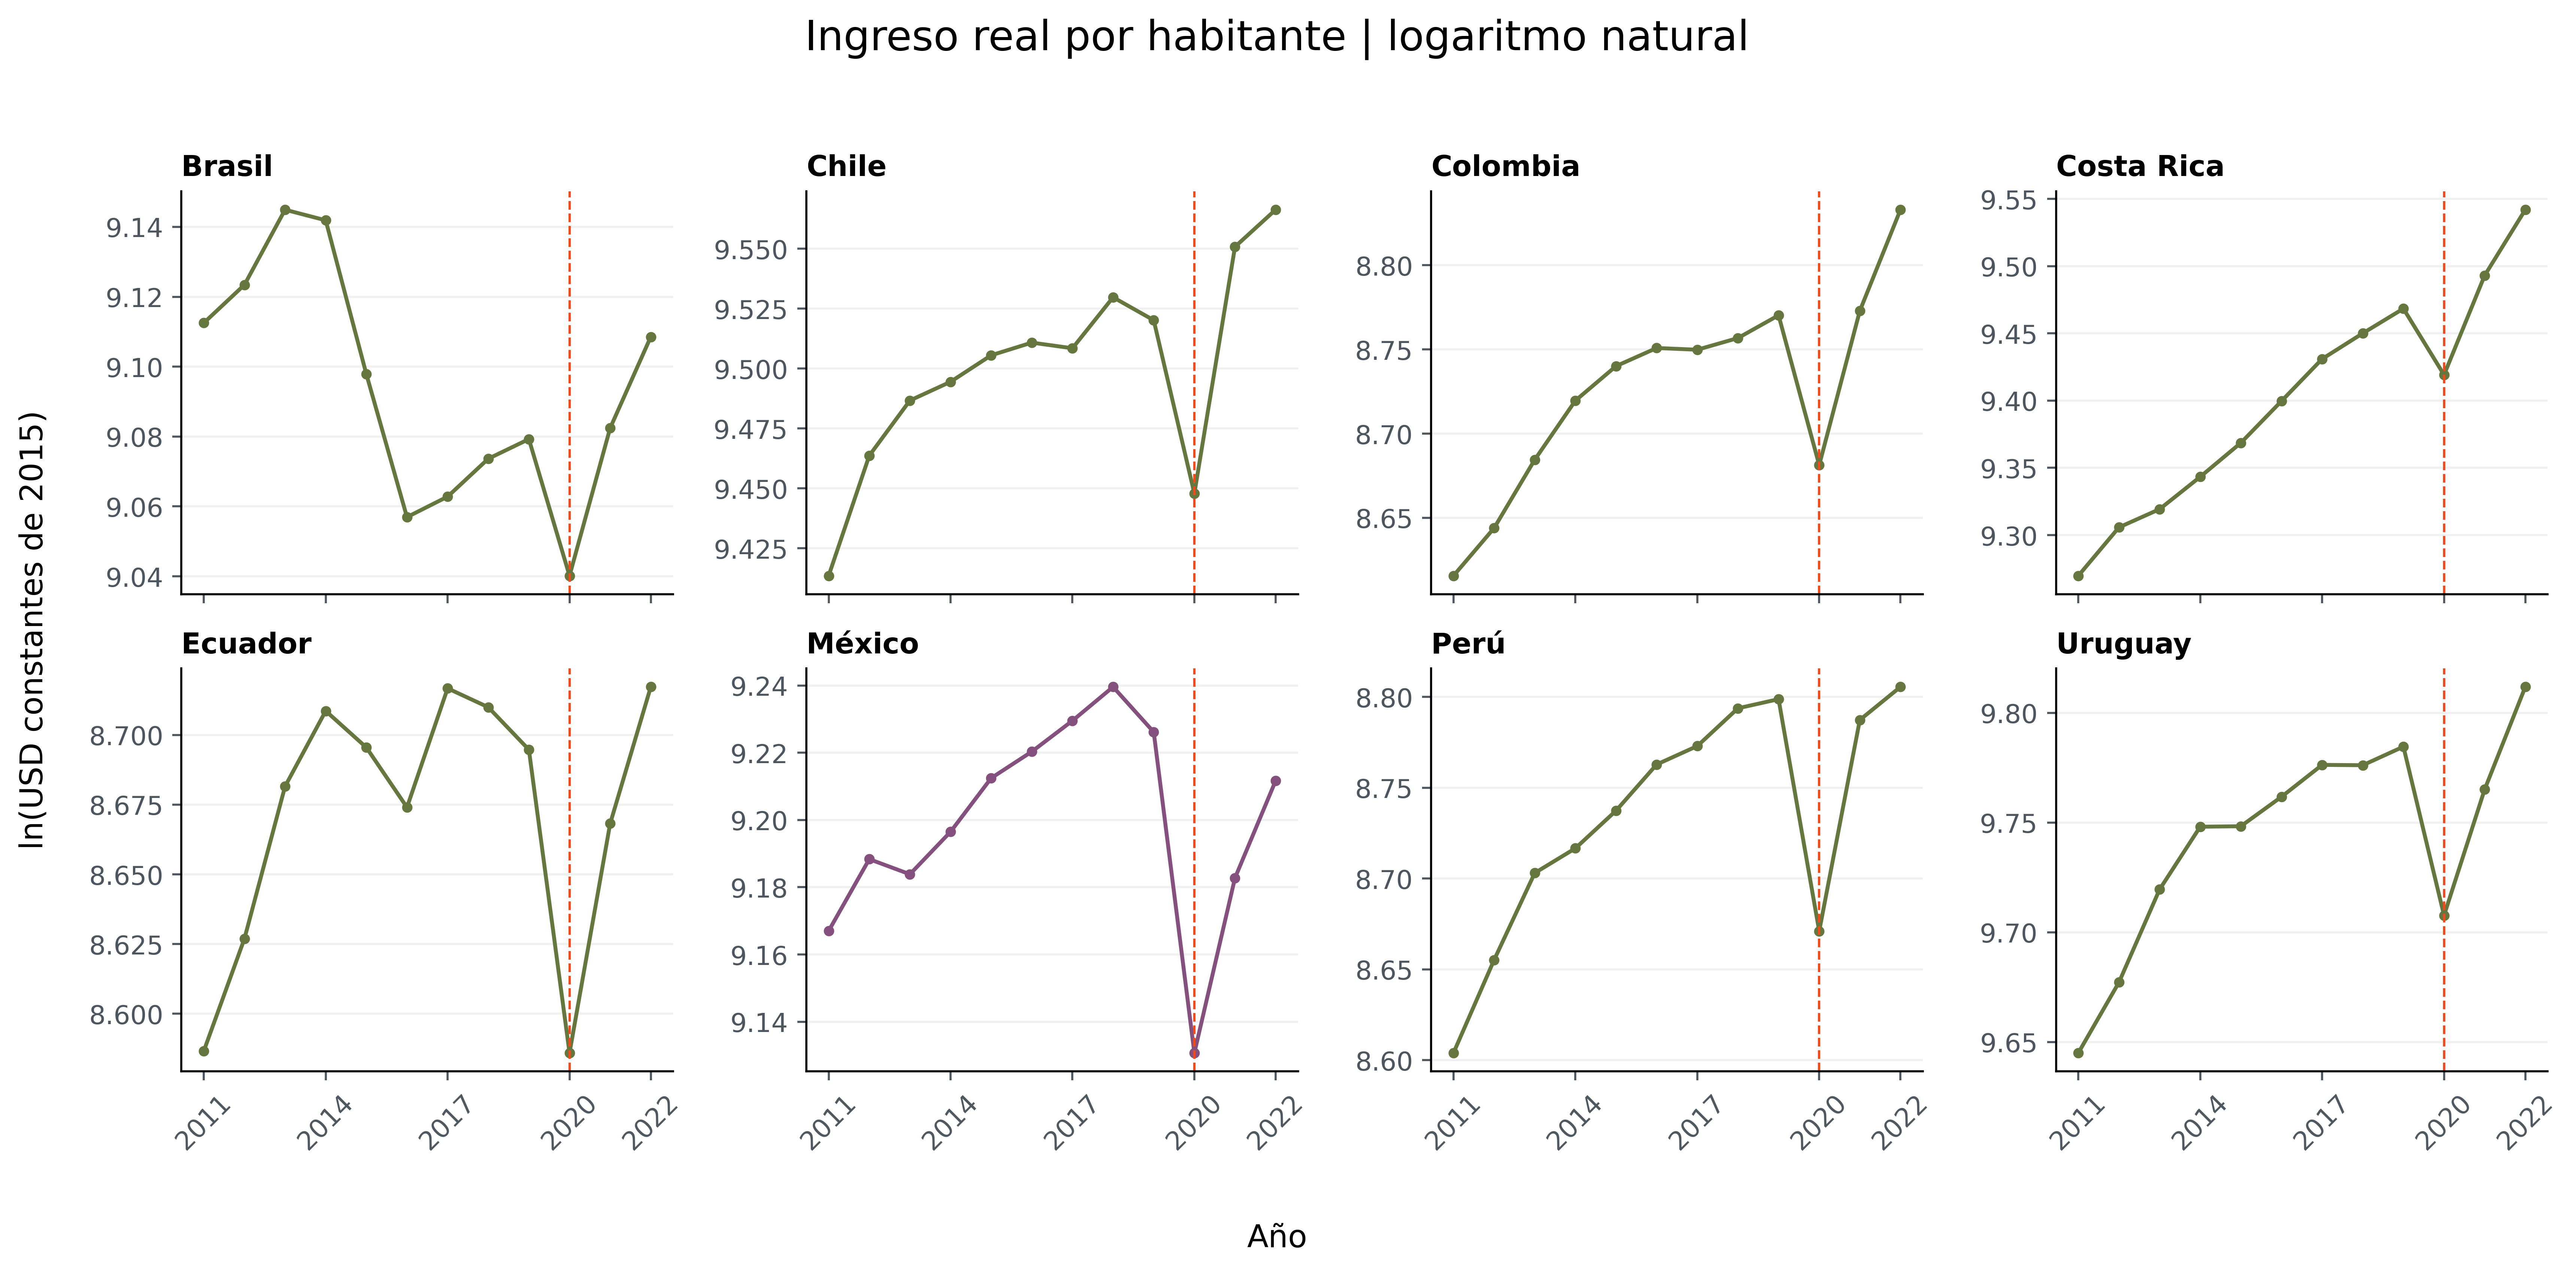

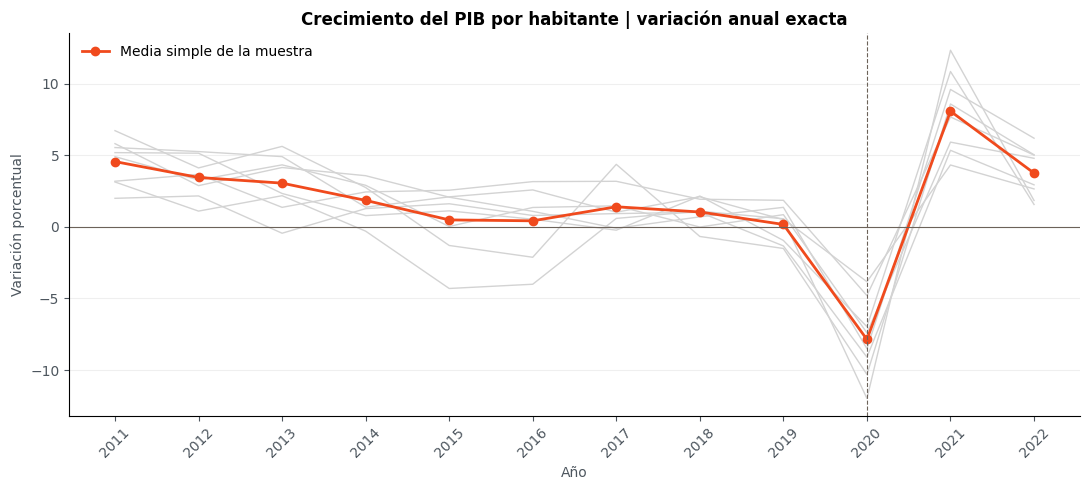


8. Una media simple de 8 países no es el crecimiento oficial de América Latina.
Los cambios de 2020 motivan controles temporales; no identifican por sí solos un efecto causal.


In [22]:
cols_fig = min(4, N)
rows_fig = int(np.ceil(N/cols_fig))
fig, ejes = plt.subplots(rows_fig, cols_fig, figsize=(14, 3.4*rows_fig), sharex=True, squeeze=False, dpi = 500)
for ax, p in zip(ejes.ravel(), paises):
    sub = Panel.loc[Panel.pais.eq(p)]
    color_pais = "#84517F" if p == "MEX" else "#65773E"
    ax.plot(sub.anio, sub.ln_pib_pc, color=color_pais, marker="o", markersize=3)
    ax.axvline(2020, color=EDL_NARANJA, linestyle="--", linewidth=.9)
    ax.set_title(Nombres.get(p, p), loc="left", fontsize=11)
    ax.set_xticks(sorted(set(anios[::3]+[anios[-1]])))
    ax.grid(axis="y", alpha=.18)
    ax.tick_params(axis="x", rotation=45)
for ax in ejes.ravel()[N:]:
    ax.set_visible(False)
fig.suptitle("Ingreso real por habitante | logaritmo natural", fontsize=16)
fig.supxlabel("Año"); fig.supylabel("ln(USD constantes de 2015)")
fig.tight_layout(rect=(.02, .02, 1, .95))
fig.savefig(SALIDA / "G02_series_ingreso.png", dpi=500, bbox_inches="tight")
fig.savefig(SALIDA / "G02_series_ingreso.svg", bbox_inches="tight")
if MOSTRAR_GRAFICOS:
    plt.show()
plt.close(fig)
Crecimientos = Panel.pivot(index="anio", columns="pais", values="crecimiento_pct")
fig, ax = plt.subplots(figsize=(11, 5))
for p in paises:
    ax.plot(Crecimientos.index, Crecimientos[p], color=EDL_APOYO, linewidth=1)
ax.plot(Crecimientos.index, Crecimientos.mean(axis=1), color=EDL_NARANJA,
        marker="o", linewidth=2, label="Media simple de la muestra")
ax.axhline(0, color=EDL_GRIS, linewidth=.8); ax.axvline(2020, color=EDL_GRIS, linestyle="--", linewidth=.8)
ax.set(title="Crecimiento del PIB por habitante | variación anual exacta",
       xlabel="Año", ylabel="Variación porcentual")
ax.set_xticks(anios)
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False); ax.grid(axis="y", alpha=.2)
fig.tight_layout();fig.savefig(SALIDA / "G03_crecimiento_comun.png", dpi=500, bbox_inches="tight")
fig.savefig(SALIDA / "G03_crecimiento_comun.svg", bbox_inches="tight")
if MOSTRAR_GRAFICOS:
    plt.show()
plt.close(fig)
print("\n8. Una media simple de 8 países no es el crecimiento oficial de América Latina.")
print("Los cambios de 2020 motivan controles temporales; no identifican por sí solos un efecto causal.")


#### **Pruebas de estacionriedad**

In [23]:
filas_raices = []
for p, sub in Panel.groupby("pais"):
    for v, determinista in [("ln_pib_pc", "ct"), ("d_ln_pib_pc", "c")]:
        # Elegir el tramo consecutivo MÁS LARGO; no comprimir huecos en el tiempo.
        sub = sub.sort_values("anio").copy()
        segmentos = sub.anio.diff().ne(1).cumsum()
        segmento = segmentos.value_counts().idxmax()
        serie = sub.loc[segmentos.eq(segmento), v].dropna().to_numpy()
        if len(serie)<8 or np.std(serie)<1e-12:
            continue
        for lag_adf in [0, 1]:
            advertencias = []
            try:
                with warnings.catch_warnings(record=True) as avisos:
                    warnings.simplefilter("always")
                    adf = adfuller(serie, maxlag=lag_adf, autolag=None, regression=determinista)
                    if lag_adf == 0:
                        kp = kpss(serie, regression=determinista, nlags=1)
                    advertencias = [str(a.message).replace("\n", " ") for a in avisos]
                filas_raices.append({"pais": p, "Variable": v, "Determinista": determinista,
                    "T_serie": len(serie), "Rezagos_ADF": lag_adf, "ADF": adf[0], "p_ADF": adf[1],
                    "KPSS": kp[0] if lag_adf==0 else np.nan,
                    "p_KPSS_tabla": kp[1] if lag_adf==0 else np.nan,
                    "Advertencia": " | ".join(advertencias)})
            except ValueError as e:
                print("Prueba no calculada:", p, v, lag_adf, str(e))
Raices = pd.DataFrame(filas_raices)
if not Raices.empty:
    # Ajuste de multiplicidad sólo sobre p ADF; KPSS tiene p acotados por tabla.
    Raices["p_ADF_Holm_todas"] = multipletests(Raices.p_ADF, method="holm")[1]
    print("\n11. Pruebas exploratorias (constante/tendencia declarada):\n",
          Raices[["pais", "Variable", "Determinista", "Rezagos_ADF", "p_ADF", "p_ADF_Holm_todas", "p_KPSS_tabla"]].round(4).to_string(index=False))
    Raices.to_csv(SALIDA / "11_ADF_KPSS_exploratorio.csv", index=False, encoding="utf-8-sig")
print("KPSS p=0.10 o 0.01 puede ser un límite de tabla: leer Advertencia, no tomarlo como p exacto.")
print("Cambiar un rezago con T corto puede cambiar mucho el resultado; no rechazar ADF no demuestra raíz unitaria.")
print("No se reporta un test de raíz unitaria de panel calibrado para dimensiones y dependencia que no tenemos.")



11. Pruebas exploratorias (constante/tendencia declarada):
 pais    Variable Determinista  Rezagos_ADF  p_ADF  p_ADF_Holm_todas  p_KPSS_tabla
 BRA   ln_pib_pc           ct            0 0.8973            1.0000        0.1000
 BRA   ln_pib_pc           ct            1 0.6756            1.0000           NaN
 BRA d_ln_pib_pc            c            0 0.1055            1.0000        0.1000
 BRA d_ln_pib_pc            c            1 0.2131            1.0000           NaN
 CHL   ln_pib_pc           ct            0 0.0980            1.0000        0.1000
 CHL   ln_pib_pc           ct            1 0.1724            1.0000           NaN
 CHL d_ln_pib_pc            c            0 0.0024            0.0745        0.1000
 CHL d_ln_pib_pc            c            1 0.0555            1.0000           NaN
 COL   ln_pib_pc           ct            0 0.4539            1.0000        0.1000
 COL   ln_pib_pc           ct            1 0.3881            1.0000           NaN
 COL d_ln_pib_pc            c        